In [1]:
#Python 3 port: put this repo's source/ folder on the import path
import os, sys
repo = os.path.abspath('.')
while not os.path.exists(os.path.join(repo, 'pyproject.toml')):
    repo = os.path.dirname(repo)
sys.path.insert(0, os.path.join(repo, 'source'))
assert os.path.isdir('output'), \
    'no output/ here: run this test first (uv run python tools/run_simulations.py ' + os.path.relpath('.', repo) + ')'

#nominal.ipynb
#by Joe Hahn, jmh.datasciences@gmail.com, 15 April 2018.
#plot evolution of self-confining ringlet
#
#epi_int_lite's runs/self_confining/nominal/nominal.ipynb (the nominal model of Hahn et al. 2025), ported to Python 3
#and run on output/ from fast/epi_int_3d.py, whose ring gravity fixes epi_int_lite issues 7 and 9. Each figure is
#followed by the original epi_int_lite run's figure from the same cell (original_figs/cellNN.png, from that
#notebook's saved outputs), for comparison by eye; the last cell compares the numbers the original printed.
#Note that fluxes.py computes the gravitational fluxes with epi_int_lite's ring gravity, as before.

In [2]:
#show the original epi_int_lite run's figure from cell number cell of the original notebook
from IPython.display import Image, Markdown, display
def show_original(cell):
    display(Markdown(f'*Original epi_int_lite run (cell {cell} of its nominal.ipynb):*'))
    display(Image(filename=f'original_figs/cell{cell:02d}.png', width=640))

In [3]:
#restore output
from helper_fns import *
exec(open('inputs.py').read())
r, t, vr, vt, times, monitor = restore_output(output_folder)
a, e, wt, M = coords2elem(J2, Rp, r, t, vr, vt)
print('r.shape = ', r.shape)
print('total_ring_mass = ', total_ring_mass)
print('shear_viscosity = ', shear_viscosity)
print('bulk_viscosity = ', bulk_viscosity)
print('initial_orbits = ', initial_orbits)
print('confine_inner_edge = ', confine_inner_edge)
print('confine_outer_edge = ', confine_outer_edge)
print('e.min() = ', e.min())
print('e.max() = ', e.max())
print('execution time (min) = ', (monitor['current_time'] - monitor['start_time'])/60.0)
print('monitor = ', monitor)

r.shape =  (1001, 2, 241)
total_ring_mass =  1e-10
shear_viscosity =  1e-13
bulk_viscosity =  1e-13
initial_orbits =  {'shape': 'eccentric', 'e': 0.01, 'e_prime': 0.0, 'w_prime': 0.0}
confine_inner_edge =  False
confine_outer_edge =  False
e.min() =  0.009740719700415216
e.max() =  0.010233080179161339
execution time (min) =  11.133333333333333
monitor =  {'start_time': 1793306292, 'current_time': 1793306960, 'current_timestep': 1700000, 'streamline_crossing_timestep': None, 'nan_timestep': None, 'self_interacting': True, 'modified_params': None}


In [4]:
a[0][1].mean()

np.float64(1.0001001598417147)

In [5]:
#time in units of viscous timescale
viscous_timescale = (radial_width**2)/(12*np.abs(shear_viscosity))
print('viscous_timescale = ', viscous_timescale)
print('viscous_timescale (orbits) = ', viscous_timescale/(2*np.pi))
times_viscous = times/viscous_timescale
print('times_viscous.max() = ', times_viscous.max())
print('number of orbits evolves (10^5) = ', times.max()/(2*np.pi)/1.0e5)

viscous_timescale =  8333.333333333332
viscous_timescale (orbits) =  1326.291192432461
times_viscous.max() =  102.00000000000001
number of orbits evolves (10^5) =  1.3528170162811104


In [6]:
#ring stats in physical units
G_cgs = 6.67e-8
M_planet_gm = 5.68e29
r0_cm = 1.0e10
total_ring_mass_gm = total_ring_mass*M_planet_gm
print('total_ring_mass_gm = ', total_ring_mass_gm)
satellite_density_cgs = 1.0                       #density if ringlet was instead a satellite
satellite_radius_cm = (3*total_ring_mass_gm/(4*np.pi*satellite_density_cgs))**(1.0/3.0)
print('satellite_radius_cm = ', satellite_radius_cm)
print('satellite_radius    (km) = ', satellite_radius_cm/1.0e5)
radial_width_cm = radial_width*r0_cm
print('radial_width_cm = ', radial_width_cm)
print('ringlet radial_width    (km) = ', radial_width_cm/1.0e5)
orbit_period_sec = 2*np.pi*np.sqrt(r0_cm*r0_cm*r0_cm/(G_cgs*M_planet_gm))
print('orbit_period_sec = ', orbit_period_sec)
print('orbit_period    (hours) = ', orbit_period_sec/3600)
viscous_timescale_sec = (viscous_timescale/(2*np.pi))*orbit_period_sec
print('viscous_timescale_sec = ', viscous_timescale_sec)
print('viscous_timescale    (years) = ', viscous_timescale_sec/(60*60*24*365.25))
shear_viscosity_cgs = radial_width_cm*radial_width_cm/(12*viscous_timescale_sec)
print('shear_viscosity_cgs = ', shear_viscosity_cgs)
surface_density_cgs = total_ring_mass_gm/(2*np.pi*r0_cm*radial_width_cm)
print('surface_density_cgs = ', surface_density_cgs)

total_ring_mass_gm =  5.68e+19
satellite_radius_cm =  2384623.9901952175
satellite_radius    (km) =  23.846239901952174
radial_width_cm =  1000000.0
ringlet radial_width    (km) =  10.0
orbit_period_sec =  32280.688093248707
orbit_period    (hours) =  8.966857803680197
viscous_timescale_sec =  42813592.303735174
viscous_timescale    (years) =  1.3566808725547943
shear_viscosity_cgs =  1946.4223590988674
surface_density_cgs =  904.0000767619655


In [7]:
#prep plots
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
color_seq = plt.rcParams['axes.prop_cycle'].by_key()['color']
from matplotlib import rcParams
import numpy as np
import pandas as pd

In [8]:
#calculate differences da, de, dwt between outer & inner streamline's periapse
from libration import *
a_inner, a_outer, a_mean, da, e_inner, e_outer, e_mean, de, wt_inner, wt_outer, dwt = \
    orbit_deltas(times, r, t, vr, vt, a, e, wt, J2, Rp)

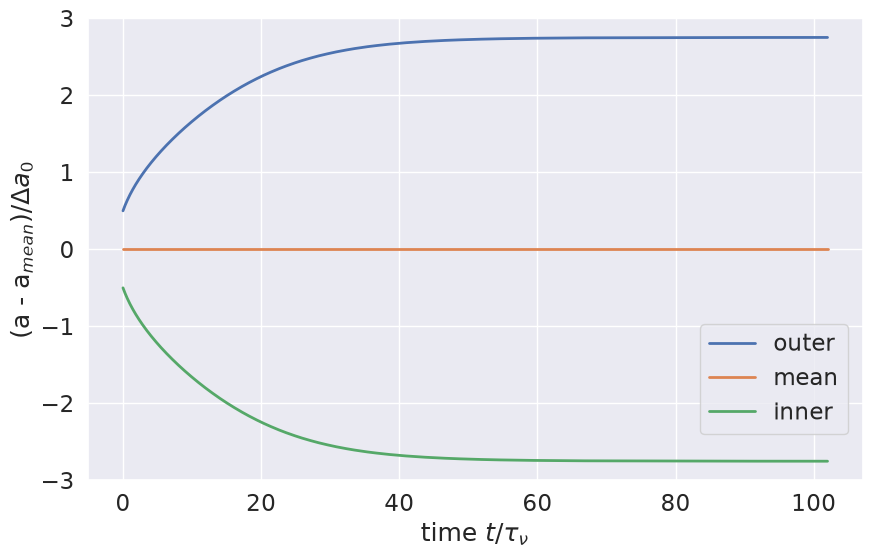

*Original epi_int_lite run (cell 7 of its nominal.ipynb):*

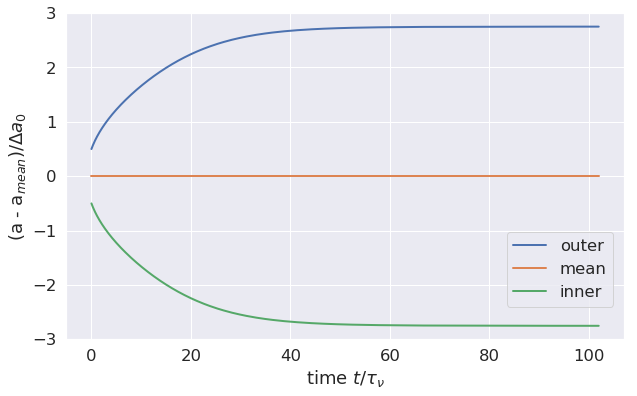

In [9]:
#plot streamline's mutual a-evolution
da_init = da[0]
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = (a_outer - a_mean)/da_init
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=1, label='outer')
y = (a_mean - a_mean)/da_init
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=1, label='mean')
y = (a_inner - a_mean)/da_init
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=1, label='inner')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r'(a - a$_{mean})/\Delta a_0$')
p = ax.legend(loc=(0.79, 0.1))
p = ax.set_ylim(-3, 3)
plt.show()
show_original(7)

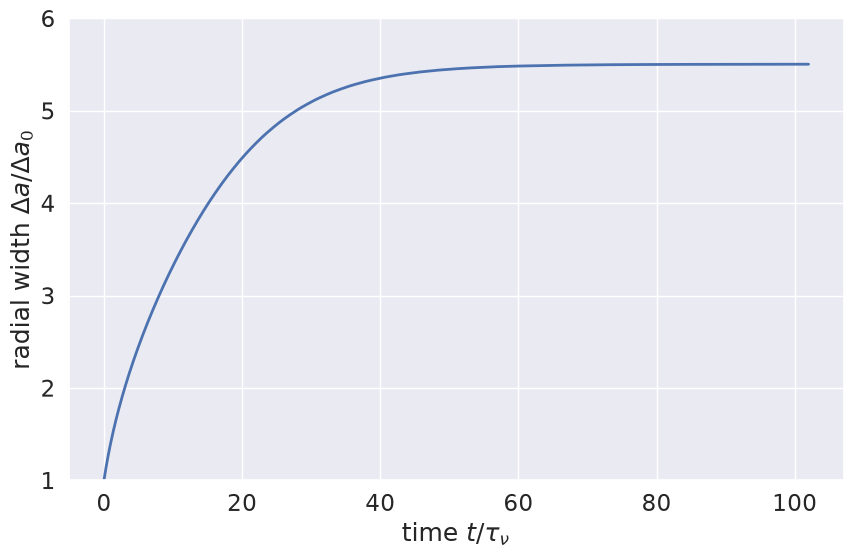

*Original epi_int_lite run (cell 8 of its nominal.ipynb):*

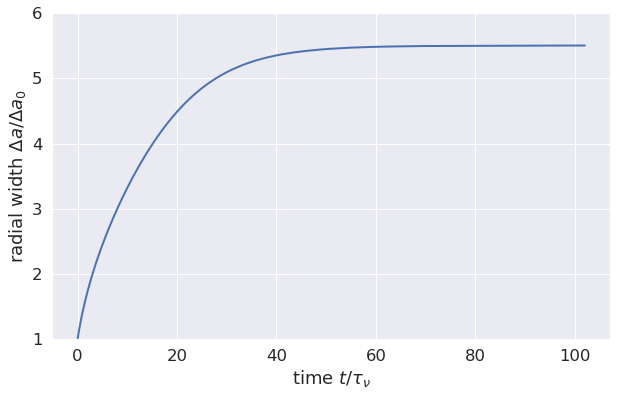

In [10]:
#plot delta_a versus time
x = times_viscous
y = da/da_init
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(x, y, linestyle='-', linewidth=2)
p = ax.set_ylabel(r'radial width $\Delta a/\Delta a_0$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylim(1, 6)
plt.show()
show_original(8)

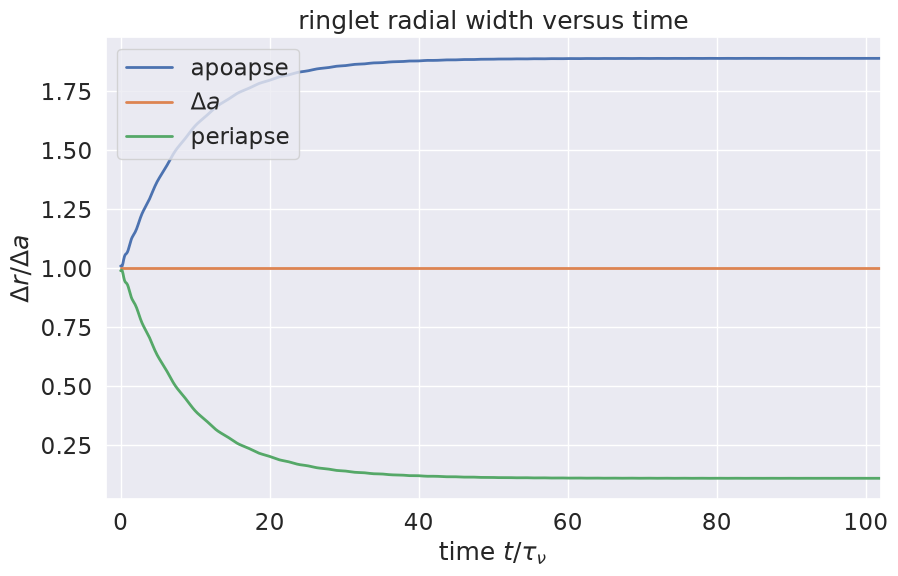

*Original epi_int_lite run (cell 9 of its nominal.ipynb):*

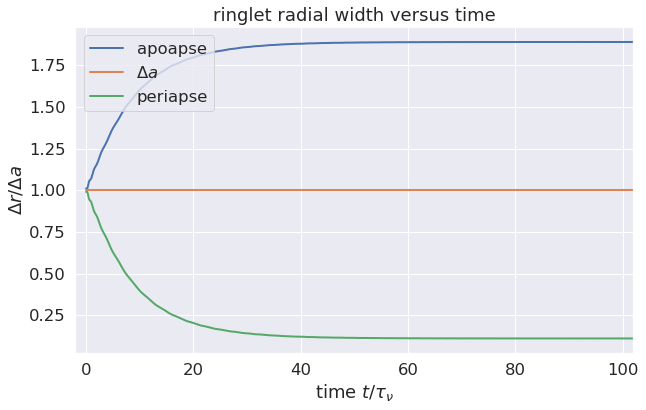

In [11]:
#plot streamline's dr_peri and dr_apo vs time
q_inner = a_inner*(1.0 - e_inner)
q_outer = a_outer*(1.0 - e_outer)
Q_inner = a_inner*(1.0 + e_inner)
Q_outer = a_outer*(1.0 + e_outer)
dr_peri = q_outer - q_inner
dr_apo = Q_outer - Q_inner
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = dr_apo/da
p = ax.plot(x, y, linestyle='-', linewidth=2, label='apoapse')
y = da/da
p = ax.plot(x, y, linestyle='-', linewidth=2, label=r'$\Delta a$')
y = dr_peri/da
p = ax.plot(x, y, linestyle='-', linewidth=2, label='periapse')
p = ax.set_title('ringlet radial width versus time')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r'$\Delta r/\Delta a$')
p = ax.set_xlim(-2, 102)
p = ax.legend()
plt.show()
show_original(9)

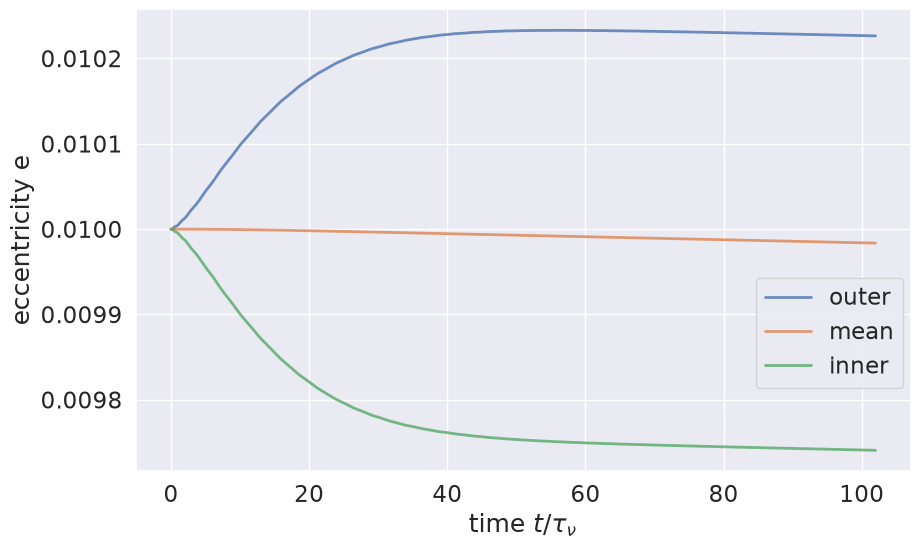

*Original epi_int_lite run (cell 10 of its nominal.ipynb):*

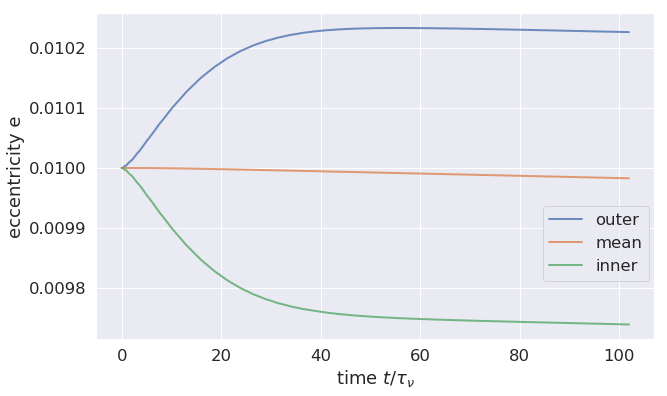

In [12]:
#plot streamline's e-evolution
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = e_outer
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=0.8, label='outer')
y = e_mean
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=0.8, label='mean')
y = e_inner
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=0.8, label='inner')
p = ax.set_ylabel('eccentricity e')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.legend(loc=(0.8, 0.18))
plt.show()
show_original(10)

1.0000500319923487 0.00999947598909294 1.001797874364802 1e-13 249967568.1953377


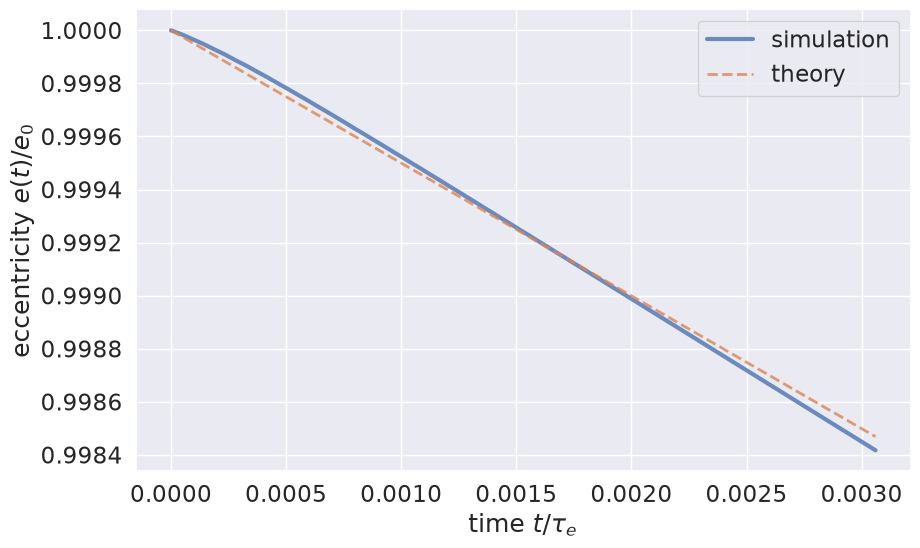

*Original epi_int_lite run (cell 11 of its nominal.ipynb):*

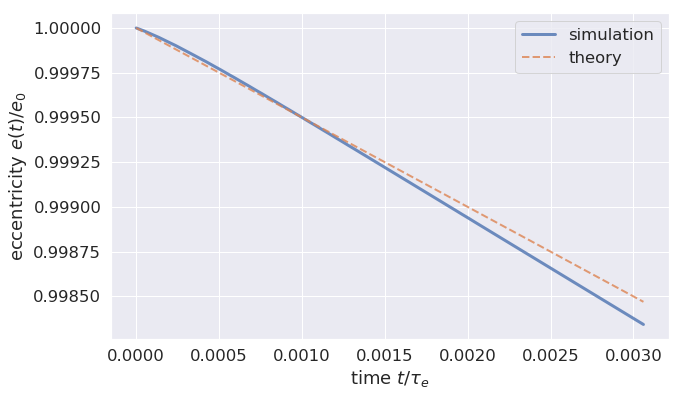

In [13]:
#plot streamline's e-damping
idx = 100
a_sub = a_mean[idx:]
e_sub = e_mean[idx:]
times_sub = times[idx:]
a0 = a_sub[0]
e0 = e_sub[0]
w0 = Omega(J2, Rp, a0)
I_ep = 0.889
tau_e = 2*a0*a0*e0*e0/(9*I_ep*shear_viscosity)
print(a0, e0, w0, shear_viscosity, tau_e)
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = (times_sub - times_sub[0])/tau_e
y = e_sub/e0
p = ax.plot(x, y, linestyle='-', linewidth=3, alpha=0.8, label='simulation')
y = np.sqrt(1 - x)
p = ax.plot(x, y, linestyle='dashed', linewidth=2, alpha=0.8, label='theory')
p = ax.set_ylabel(r'eccentricity $e(t)/e_0$')
p = ax.set_xlabel(r'time $t/\tau_e$')
p = ax.legend()
plt.show()
show_original(11)

In [14]:
#compute system total angular momentum
r_bc, t_bc, vr_bc, vt_bc, r_0, t_0, vr_0, vt_0 = planeto2bary_all_times(times, r, t, vr, vt, total_ring_mass)
planet_angular_momentum, inner_ring_angular_momentum, outer_ring_angular_momentum, total_angular_momentum = \
    system_angular_momentum(times, r_bc, t_bc, vr_bc, vt_bc, r_0, t_0, vr_0, vt_0, \
        total_ring_mass, number_of_streamlines, particles_per_streamline)
delta_angular_momentum = total_angular_momentum - total_angular_momentum[0]
fractional_angular_momentum_change = np.abs(delta_angular_momentum/total_angular_momentum[0])
print('planet_angular_momentum[0] = ', planet_angular_momentum[0])
print('total_angular_momentum[0] = ', total_angular_momentum[0])
print('max fractional angular momentum change = ', fractional_angular_momentum_change.max())

planet_angular_momentum[0] =  8.479822523390982e-27
total_angular_momentum[0] =  1.0018981045638689e-10
max fractional angular momentum change =  9.197851755175508e-08


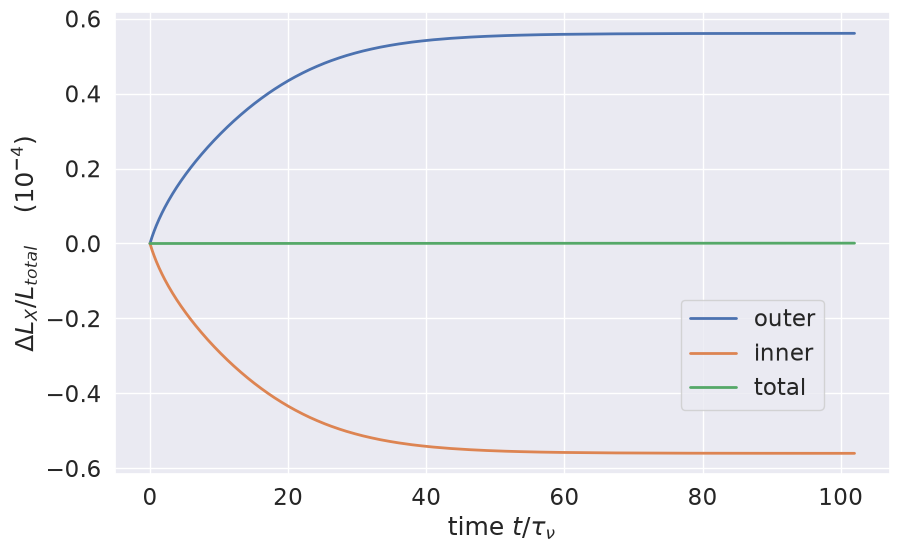

*Original epi_int_lite run (cell 13 of its nominal.ipynb):*

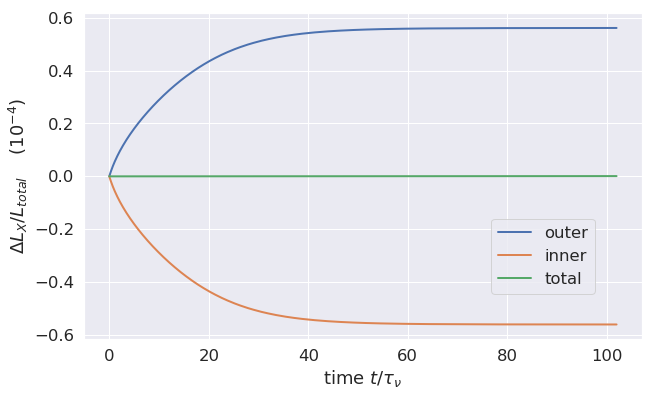

In [15]:
#plot delta_X_angular_momentum over time, for X=inner/outer streamline
factor = (1.0e-4)*total_angular_momentum[0]
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = (outer_ring_angular_momentum - outer_ring_angular_momentum[0])/factor
p = ax.plot(x, y, linestyle='-', linewidth=2, label='outer')
y = (inner_ring_angular_momentum - inner_ring_angular_momentum[0])/factor
p = ax.plot(x, y, linestyle='-', linewidth=2, label='inner')
y = (total_angular_momentum - total_angular_momentum[0])/factor
p = ax.plot(x, y, linestyle='-', linewidth=2, label='total')
p = ax.set_ylabel(r'$\Delta L_X/L_{total}$    $(10^{-4})$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.legend(loc=(0.73, 0.14))
plt.show()
show_original(13)

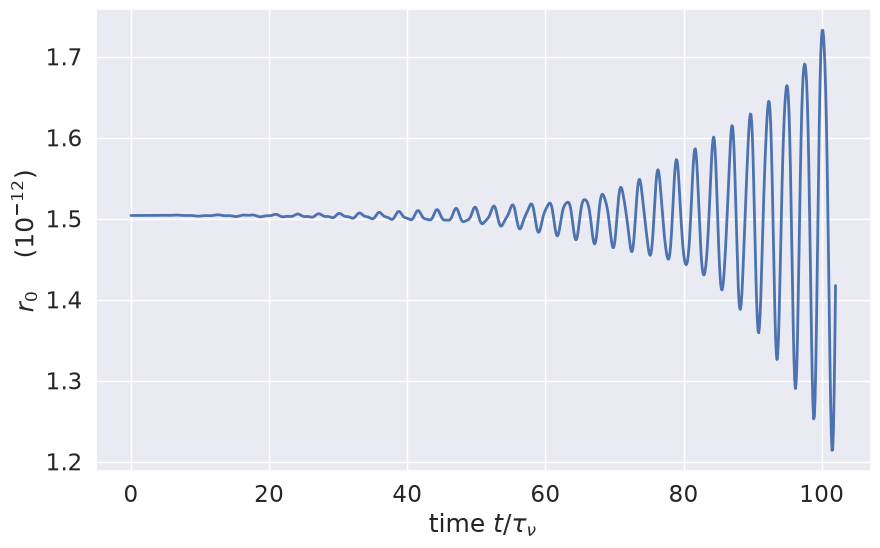

*Original epi_int_lite run (cell 14 of its nominal.ipynb):*

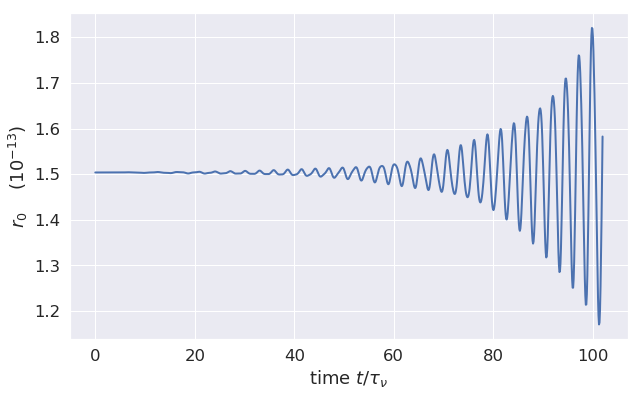

In [16]:
#central planet's distance from barycenter
factor = 1.0e-12
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = r_0/factor
p = ax.plot(x, y, linestyle='-', linewidth=2)
p = ax.set_ylabel(r'$r_0$    $(10^{-12})$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
plt.show()
show_original(14)

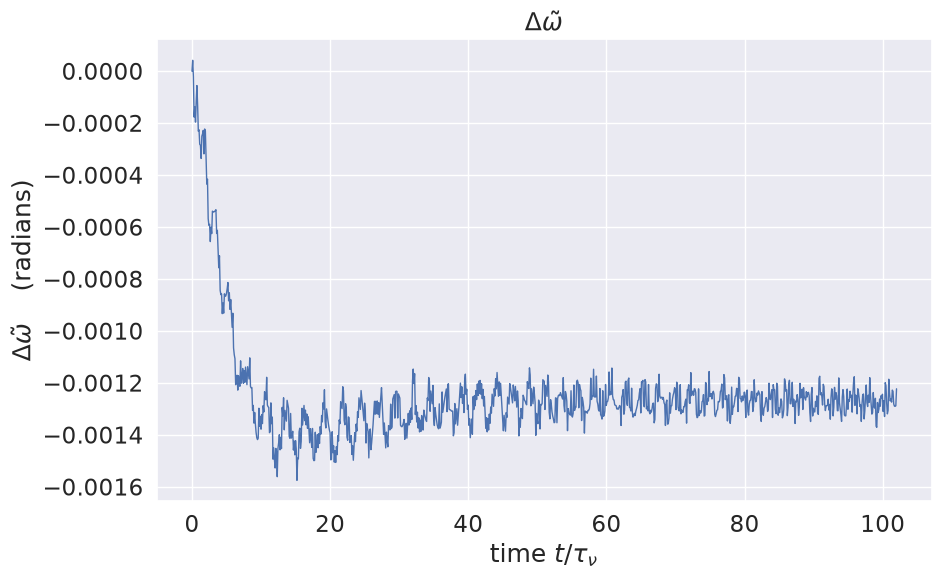

*Original epi_int_lite run (cell 15 of its nominal.ipynb):*

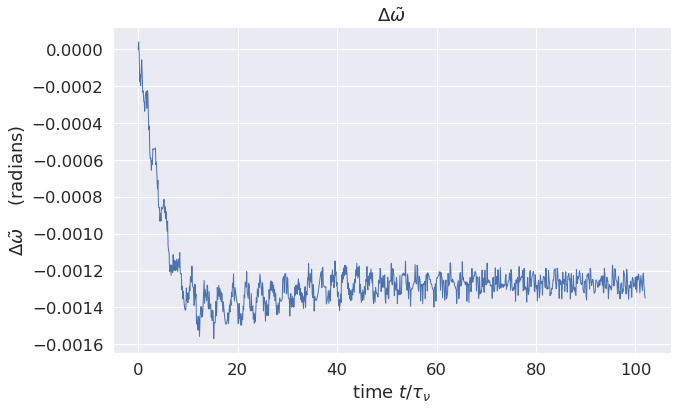

In [17]:
#plot dwt versus time
x = times_viscous
y = dwt
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(x, y, linestyle='-', linewidth=1)
p = ax.set_title(r'$\Delta\tilde{\omega}$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r'$\Delta\tilde{\omega}$    (radians)')
plt.show()
show_original(15)

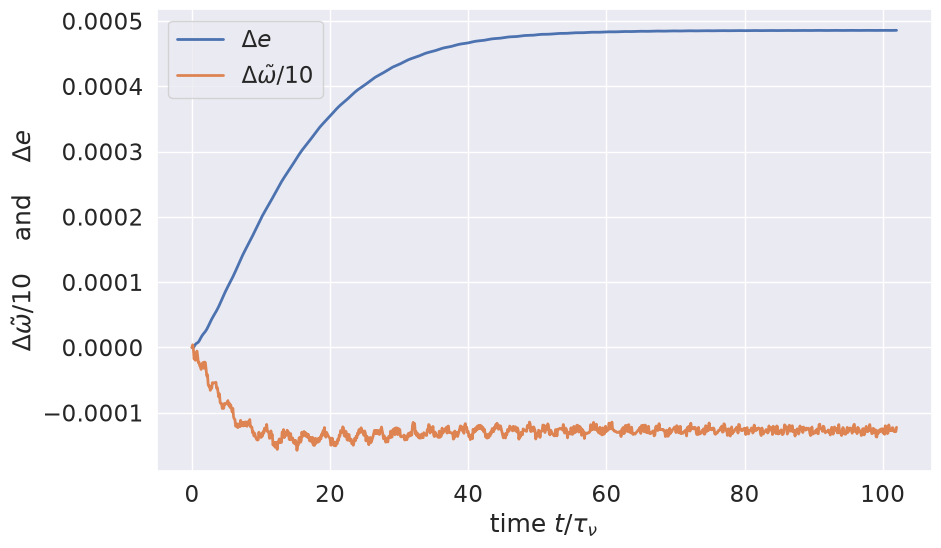

*Original epi_int_lite run (cell 16 of its nominal.ipynb):*

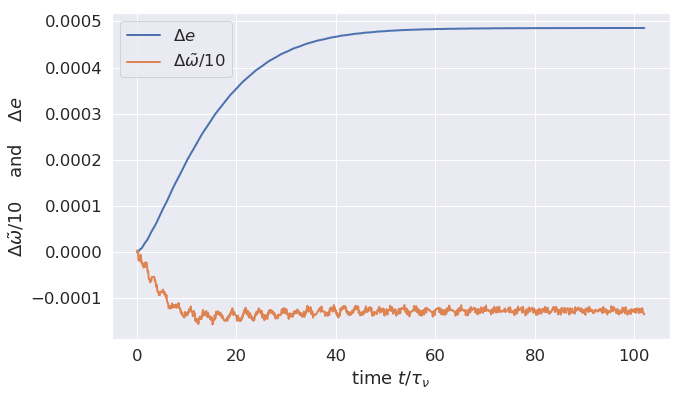

In [18]:
#plot de and dwt aversus time
x = times_viscous
y = de
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(x, y, linestyle='-', linewidth=2, label=r'$\Delta e$')
y = dwt/10
p = ax.plot(x, y, linestyle='-', linewidth=2, label=r'$\Delta\tilde{\omega}/10$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r'$\Delta\tilde{\omega}/10$    and    $\Delta e$')
p = ax.legend()
plt.show()
show_original(16)

In [19]:
#compute e_prime, wt_prime, q to lowest order, and H(q)
H, q, e_prime, wt_prime = calculate_Hq(a_mean, e_mean, da, de, dwt)
H_avg = H.mean()

dynamical_timescale =  85000.0
timesteps_per_output_factor =  1.0


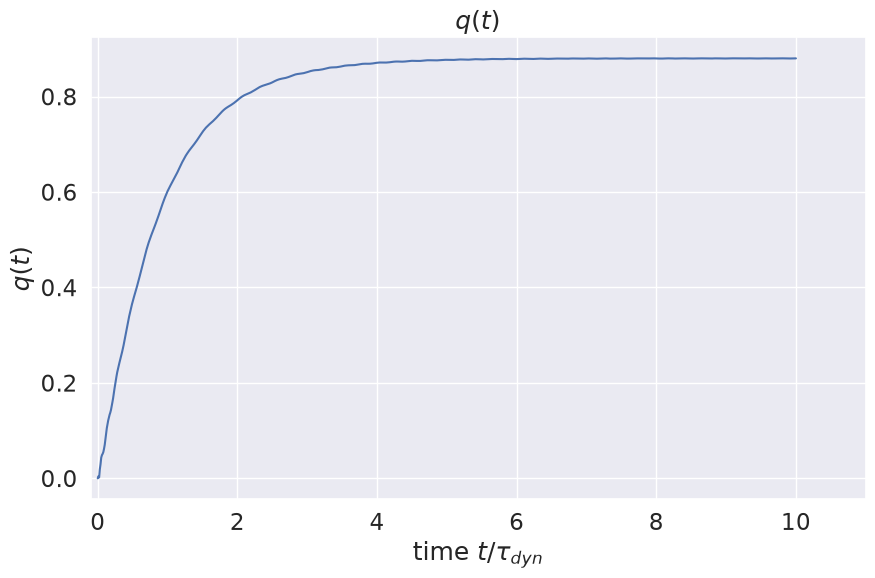

*Original epi_int_lite run (cell 18 of its nominal.ipynb):*

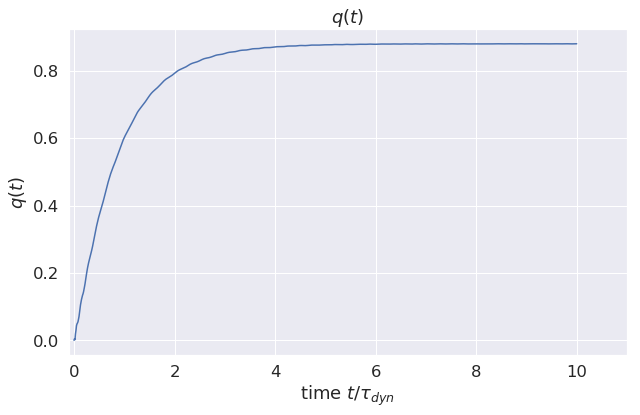

In [20]:
#dynamical timescale=time when ringlet achieves q=0.6, this ringlet is to be evolved until t=20*t_dyn
idx = (q > 0.6)
dynamical_timescale = times[idx][0]
print('dynamical_timescale = ', dynamical_timescale)
timesteps_per_output_factor = 10*dynamical_timescale/times.max()
print('timesteps_per_output_factor = ', timesteps_per_output_factor)
x = times/dynamical_timescale
y = q
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(x, y, linestyle='-')
p = ax.set_title(r'$q(t)$')
p = ax.set_xlabel(r'time $t/\tau_{dyn}$')
p = ax.set_ylabel(r'$q(t)$')
p = ax.set_xlim(-0.1, 11.0)
plt.show()
show_original(18)

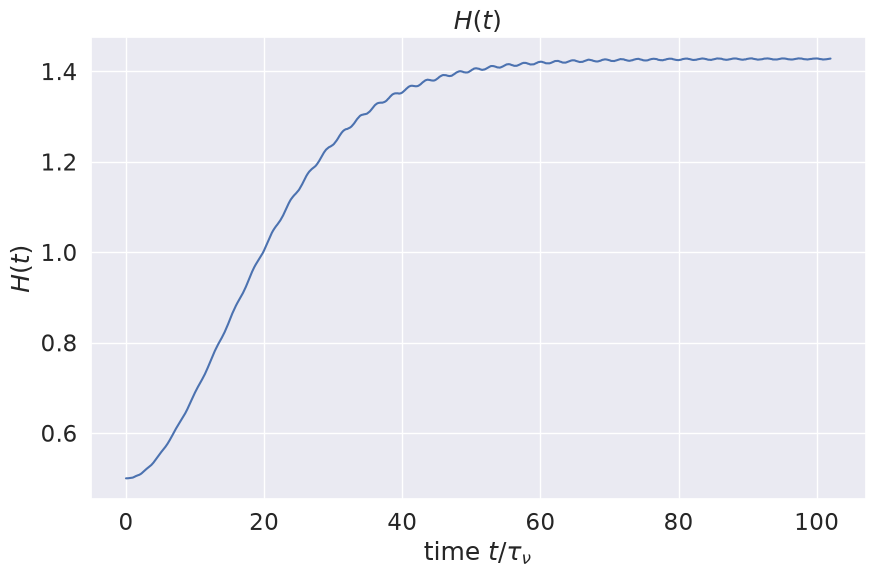

*Original epi_int_lite run (cell 19 of its nominal.ipynb):*

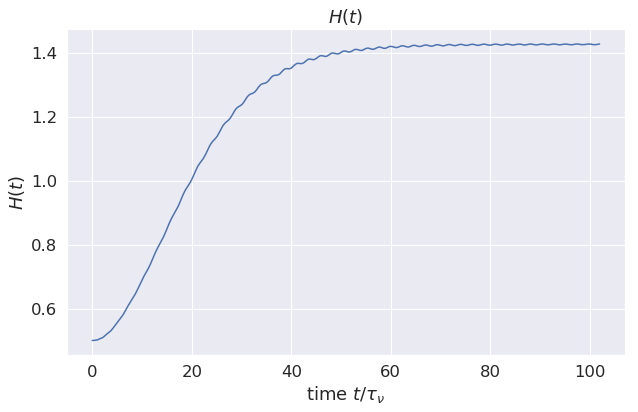

In [21]:
#plot H(q) versus time
x = times_viscous
y = H
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(x, y, linestyle='-')
p = ax.set_title(r'$H(t)$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r'$H(t)$')
plt.show()
show_original(19)

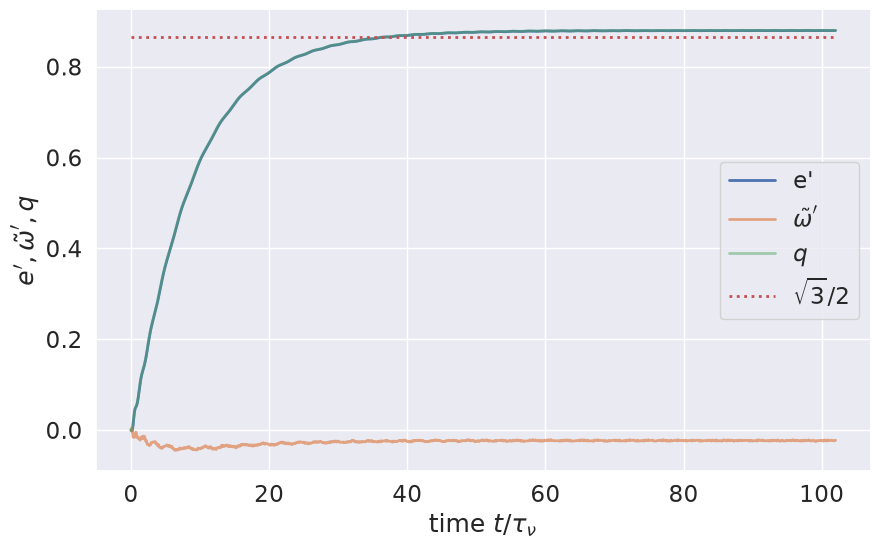

*Original epi_int_lite run (cell 20 of its nominal.ipynb):*

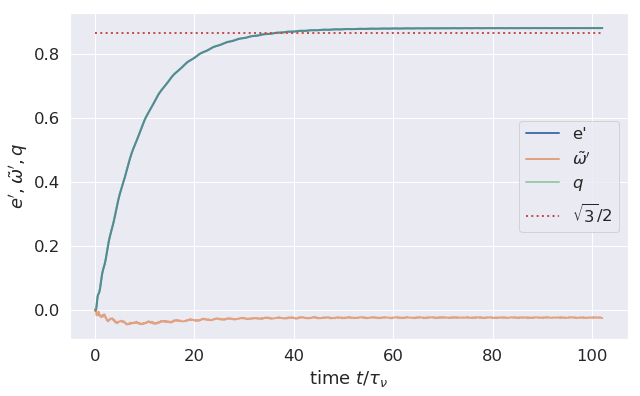

In [22]:
#plot e_prime wt_prime and q versus time
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = e_prime
p = ax.plot(x, y, linestyle='-', linewidth=2, label="e'")
y = wt_prime
p = ax.plot(x, y, linestyle='-', linewidth=2, alpha=0.7, label=r"$\tilde{\omega}'$")
y = q
p = ax.plot(x, y, linestyle='-', linewidth=2, label=r'$q$', alpha=0.5)
p = ax.plot(x, x*0 + np.sqrt(3.0)/2.0, linestyle='dotted', linewidth=2, label=r"$\sqrt{3}/2$")
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r"$e', \tilde{\omega}', q$")
p = ax.legend()
plt.show()
show_original(20)

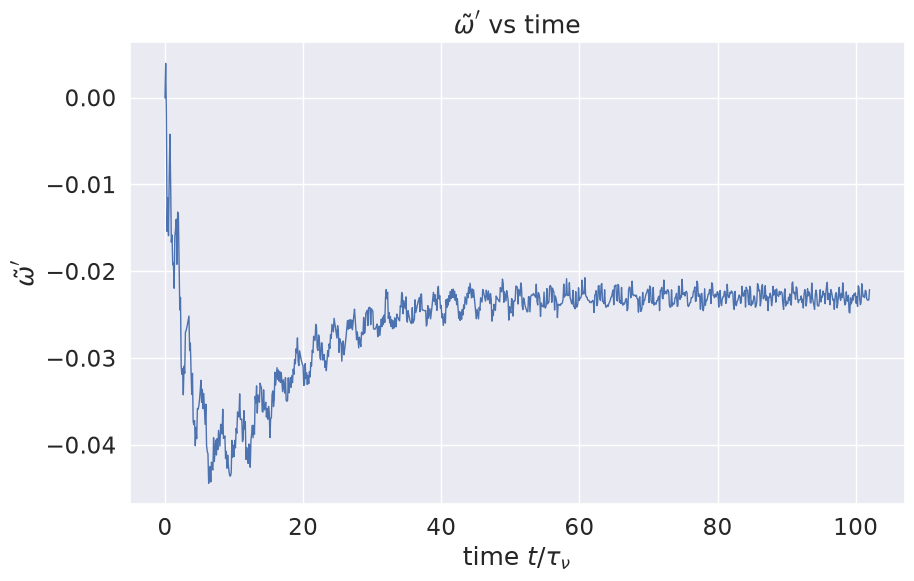

*Original epi_int_lite run (cell 21 of its nominal.ipynb):*

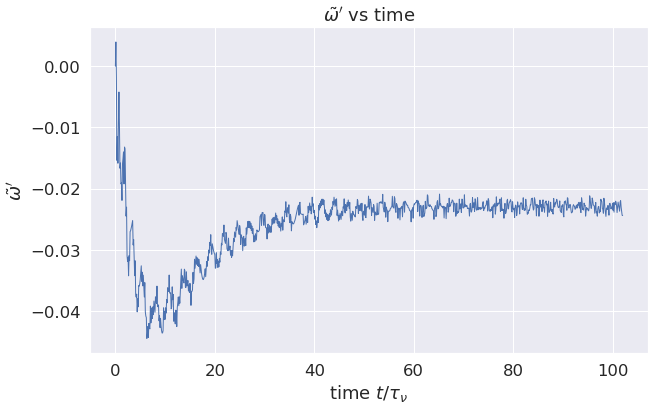

In [23]:
#plot wt_prime versus time
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = wt_prime
p = ax.plot(x, y, linestyle='-', linewidth=1)
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylabel(r"$\tilde{\omega}'$")
p = ax.set_title(r"$\tilde{\omega}'$ vs time")
plt.show()
show_original(21)

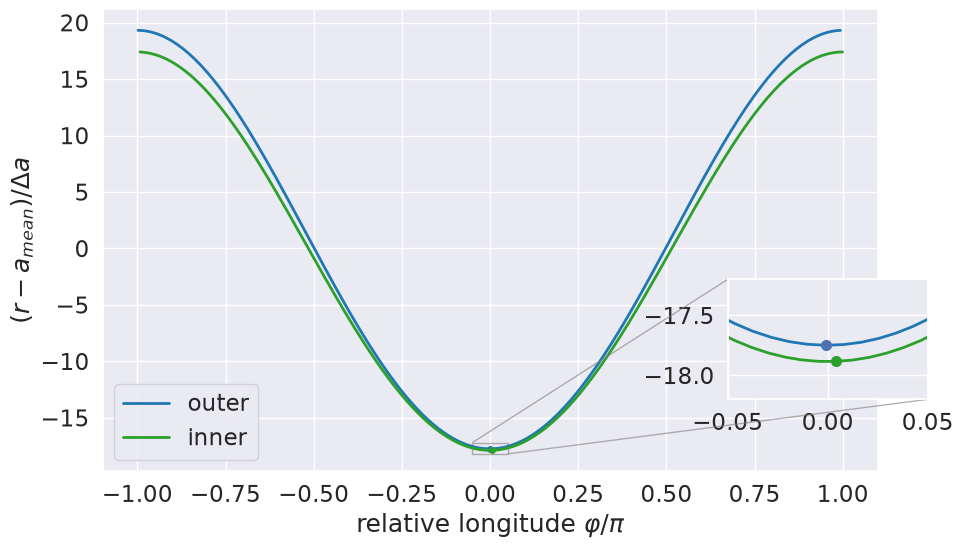

*Original epi_int_lite run (cell 22 of its nominal.ipynb):*

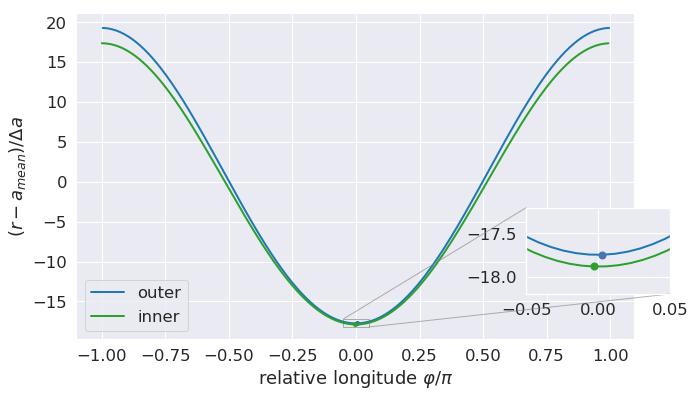

In [24]:
#plot streamlines planetocentric distance versus relative longitude
#i dont this this plot/calcuation is correct...
tidx = len(times) - 1
r1, t1, vr1, vt1, wt1 = peri_corotate(r[tidx].copy(), t[tidx].copy(), vr[tidx].copy(), vt[tidx].copy(),
    wt[tidx].copy())
a1 = a_mean[tidx]
da1 = da[tidx]
xp = t1/np.pi
yp = (r1 - a1)/da1
sns.set(font_scale=1.5, font='DejaVu Sans')
fig, ax = plt.subplots(figsize=(10, 6))
left, bottom, width, height = [0.75, 0.23, 0.2, 0.2]
ax_inset = fig.add_axes([left, bottom, width, height])
idx = 1
color = color_seq[0]
jdx = r1[idx].argmin()
p = ax.plot(xp[idx], yp[idx], linestyle='-', linewidth=2, color=color, label='outer')
p = ax_inset.plot(xp[idx], yp[idx], linestyle='-', linewidth=2, color=color)
p = ax.plot(xp[idx][jdx], yp[idx][jdx], marker='o', markersize=4, color=color, label='')
p = ax_inset.plot(xp[idx][jdx], yp[idx][jdx], marker='o', markersize=7, label='')
idx = 0
color = color_seq[2]
jdx = r1[idx].argmin()
p = ax.plot(xp[idx], yp[idx], linestyle='-', linewidth=2, color=color, label='inner')
p = ax_inset.plot(xp[idx], yp[idx], linestyle='-', linewidth=2, color=color)
p = ax.plot(xp[idx][jdx], yp[idx][jdx], marker='o', markersize=4, color=color, label='')
p = ax_inset.plot(xp[idx][jdx], yp[idx][jdx], marker='o', markersize=7, color=color, label='')
p = ax.set_xlabel(r'relative longitude $\varphi/\pi$')
p = ax.set_ylabel(r'$(r - a_{mean})/\Delta a$')
p = ax_inset.set_xlim(-0.05, 0.05)
p = ax_inset.set_ylim(-18.2, -17.2)
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
mark_inset(ax, ax_inset, loc1=2, loc2=4, edgecolor='gray', alpha=0.6)
p = ax.legend()
plt.show()
show_original(22)

e' =  5.568970177210566e-05
e' =  0.3994079508822567
e' =  0.6460281249069265
e' =  0.7783951726936872
e' =  0.8796356351451763


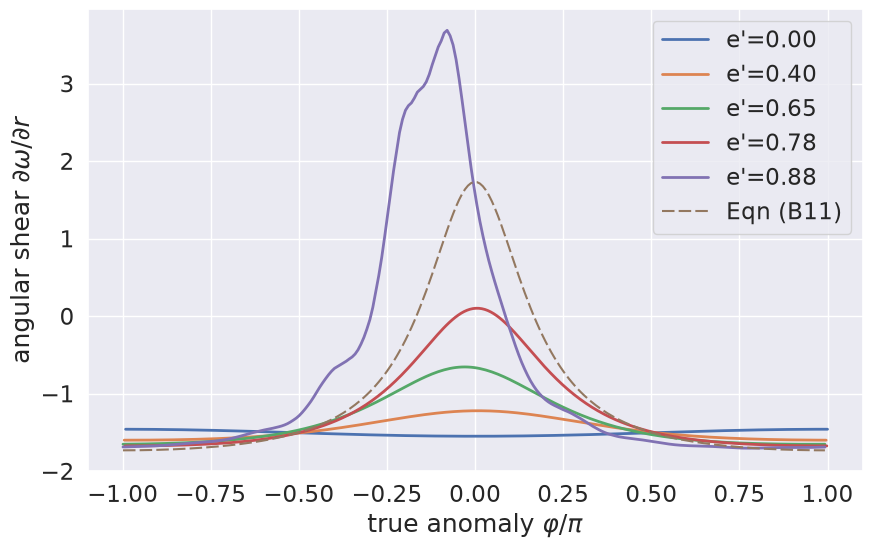

*Original epi_int_lite run (cell 23 of its nominal.ipynb):*

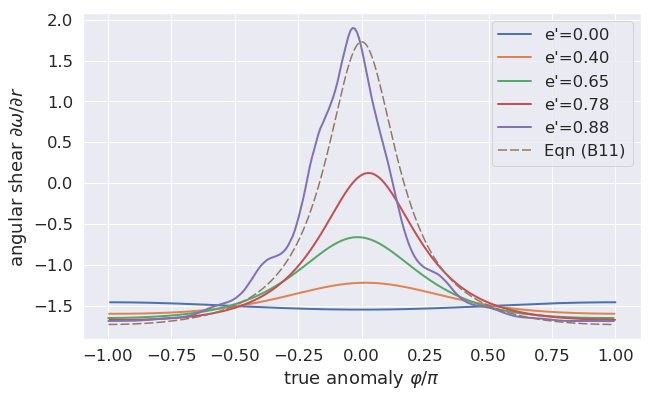

In [25]:
#show that angular shear reverses sign when eccentricity gradient gets large enough
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
for tidx, lbl in ((0, "e'=0.00"), (56, "e'=0.40"), (116, "e'=0.65"), (187, "e'=0.78"), (702, "e'=0.88")):
    print("e' = ", e_prime[tidx])
    r1, t1, vr1, vt1, wt1 = peri_corotate(r[tidx].copy(), t[tidx].copy(), vr[tidx].copy(), vt[tidx].copy(),
        wt[tidx].copy())
    omega = vt1/r1
    delta_omega = omega[1] - omega[0]
    delta_r = r1[1] - r1[0]
    dw_dr = delta_omega/delta_r
    xp = t1[0]/np.pi
    yp = dw_dr
    p = ax.plot(xp, yp, linestyle='-', linewidth=2, label=lbl)
ep = np.sqrt(3.0)/2.0
M = xp*np.pi
ep_cosM = ep*np.cos(M)
yp = -(3.0/2.0)*(1 - 4*ep_cosM/3)/(1 - ep_cosM)
p = ax.plot(xp, yp, linestyle='dashed', dashes=[6, 2], linewidth=1.5, label="Eqn (B11)")
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'angular shear $\partial\omega/\partial r$')
p = plt.legend()
plt.show()
show_original(23)

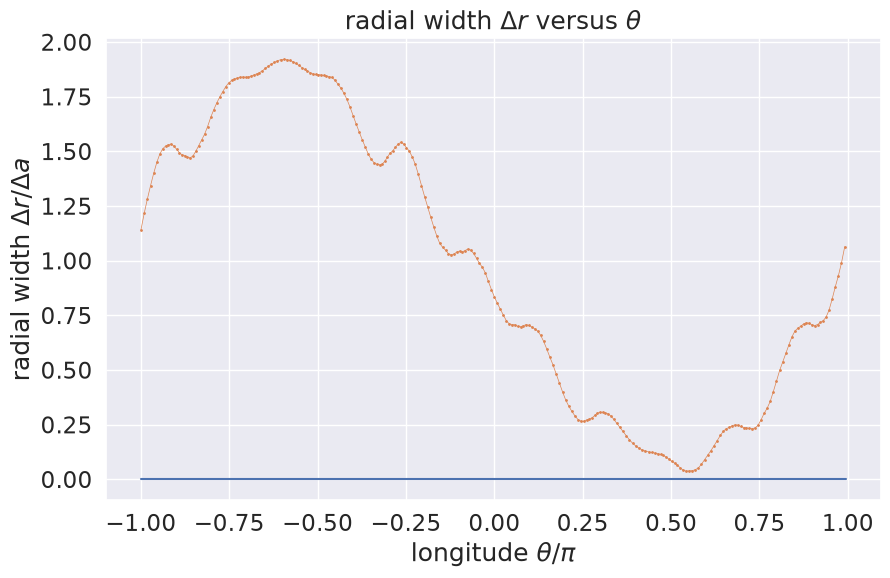

*Original epi_int_lite run (cell 24 of its nominal.ipynb):*

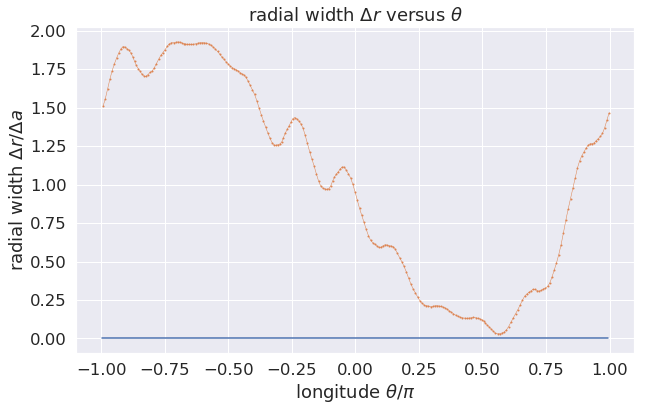

In [26]:
#inspect final radial width versus longitude
tidx = len(times) - 1
rt = r[tidx]
r0 = rt[0]
r1 = rt[1] - r0
r0 = r0 - r0
at = a[tidx]
a0 = at[0]
a1 = at[1]
delta_a = a1.mean() - a0.mean()
tt = t[tidx]
t0 = tt[0]
t1 = tt[1]
f, ax = plt.subplots(figsize=(10, 6))
x = t0/np.pi
y = r0/delta_a
p = ax.plot(x, y, linestyle='-')
x = t1/np.pi
y = r1/delta_a
p = ax.plot(x, y, linestyle='-', linewidth=0.5, marker='.', markersize=2)
p = ax.set_title(r'radial width $\Delta r$ versus $\theta$')
p = ax.set_xlabel(r'longitude $\theta/\pi$')
p = ax.set_ylabel(r'radial width $\Delta r/\Delta a$')
plt.show()
show_original(24)

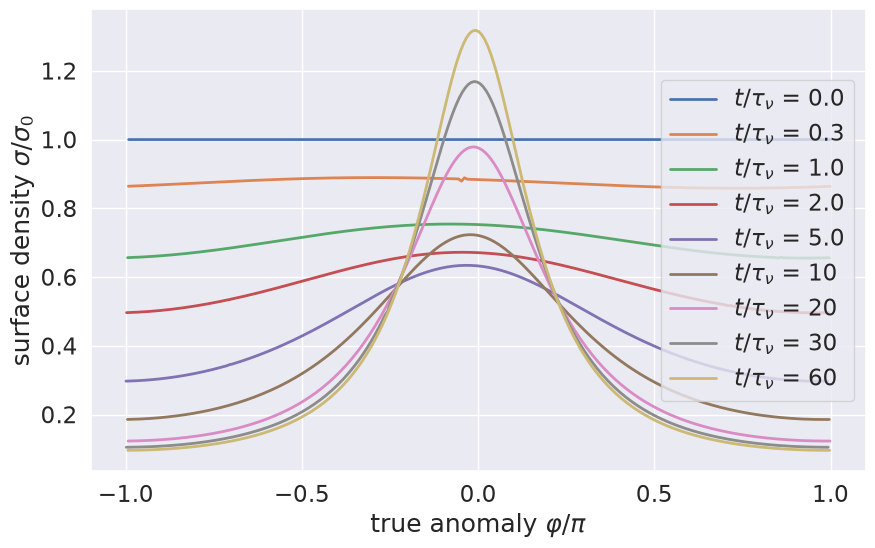

*Original epi_int_lite run (cell 25 of its nominal.ipynb):*

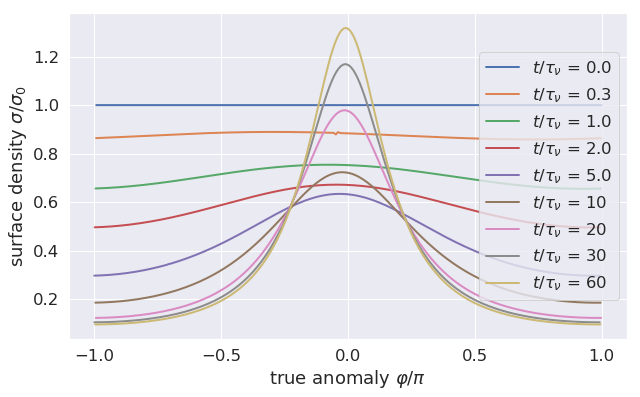

In [27]:
#plot surface density vs longitude
sns.set(font_scale=1.5, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
plot_times = [0.0, 0.3, 1.0, 2.0, 4.99, 10.0, 20.0, 30.0, 60.0]
middle_index = number_of_streamlines//2
for plot_time in plot_times:
    t_idx = np.where(times_viscous >= plot_time)[0][0]
    r_now = r[t_idx]
    t_now = t[t_idx]
    vr_now = vr[t_idx]
    vt_now = vt[t_idx]
    wt_now = wt[t_idx]
    lambda_ = get_lambda(total_ring_mass, number_of_streamlines, J2, Rp, r_now, t_now, vr_now, vt_now)
    delta_r = delta_f(r_now, t_now)
    sd_now = surface_density(lambda_, delta_r)
    r_middle = r_now[middle_index]
    t_middle = t_now[middle_index]
    wt_middle = wt_now[middle_index]
    sd_middle = sd_now[middle_index]
    pidx = r_middle.argmin()
    wt_min = wt_middle[pidx]
    t_rotating = adjust_angle(t_middle - wt_min)
    if (t_idx == 0):
        sd_initial = sd_now.mean()
    y = sd_middle/sd_initial
    x = t_rotating/np.pi
    idx = np.argsort(t_rotating)
    x = x[idx]
    y = y[idx]
    times_visc = times_viscous[t_idx]
    if (times_visc > 1 ):
        times_visc = round(times_visc, 0)
    lbl = r'$t/\tau_\nu$ = ' + str(times_visc)[0:3]
    if (lbl[-1] == '.'):
        lbl = lbl[:-1]
    p = ax.plot(x, y, linestyle='-', linewidth=2, label=lbl)
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'surface density $\sigma/\sigma_0$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = plt.legend(loc='center right')
plt.show()
show_original(25)

relative_longitude =  0.044075385492026165 idx =  49
[0.         3.57632106 3.60426717 0.        ]
relative_longitude =  3.15778107463161 idx =  169
[0.         0.26193455 0.26189941 0.        ]
relative_longitude =  1.6054503654816008 idx =  108
[0.         0.49022398 0.49148314 0.        ]
relative_longitude =  4.788978275909697 idx =  -9
[0.         0.57151943 0.573879   0.        ]


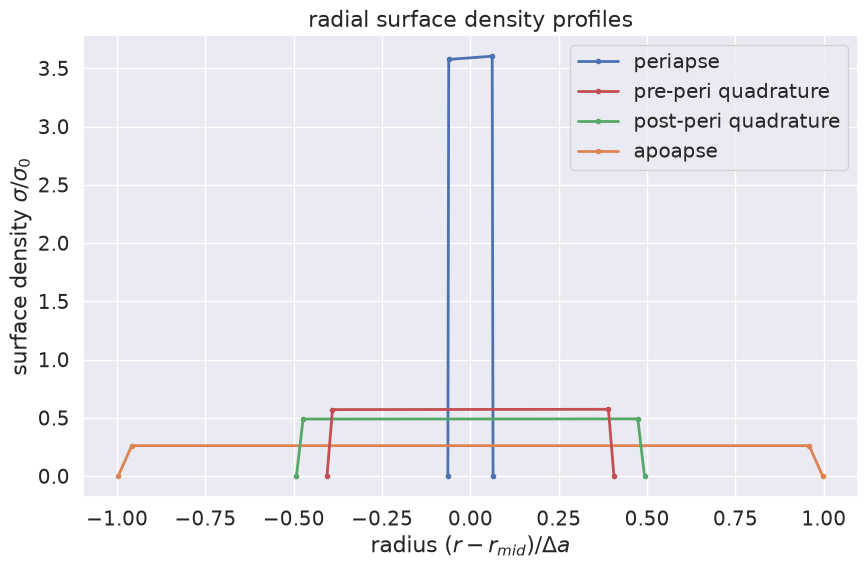

*Original epi_int_lite run (cell 26 of its nominal.ipynb):*

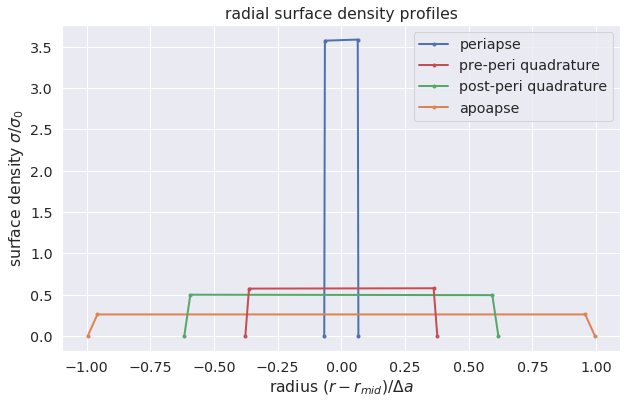

In [28]:
#plot radial cuts of surface density...surface density contrast = 3.58/0.45 = 7.96
def radial_profile(idx, lbl):
    """the radial surface density profile at particle index idx, padded with zeros at the ringlet's edges"""
    relative_longitude = (t_now - wt_now)[0][idx]
    print('relative_longitude = ', relative_longitude, 'idx = ', idx)
    r_profile = r_now[:, idx]
    sd_profile = sd_now[:, idx]
    r_padded = r_profile.tolist()
    r_padded = [r_profile[0] - 0.02*(r_profile[1] - r_profile[0])] + r_padded
    r_padded = r_padded + [r_profile[-1] + 0.02*(r_profile[-1] - r_profile[-2])]
    r_padded = np.array(r_padded) - r_profile.mean()
    sd_padded = np.array([0.0] + sd_profile.tolist() + [0.0])
    xp = r_padded/da[t_idx]
    yp = sd_padded/sd_mean
    p = ax.plot(xp, yp, linestyle='-', linewidth=2, marker='o', markersize=3, label=lbl)
    print(yp)
    return yp
sns.set(font_scale=1.3, font='DejaVu Sans')
f, ax = plt.subplots(figsize=(10, 6))
t_idx = total_number_of_outputs - 1
r_now = r[t_idx]
t_now = t[t_idx]
vr_now = vr[t_idx]
vt_now = vt[t_idx]
wt_now = wt[t_idx]
lambda_ = get_lambda(total_ring_mass, number_of_streamlines, J2, Rp, r_now, t_now, vr_now, vt_now)
delta_r = delta_f(r_now, t_now)
sd_now = surface_density(lambda_, delta_r)
sd_mean = sd_now.mean()
r_middle = r_now[middle_index]
idx_peri = r_middle.argmin() + 1                            #sd(r) along periapse
sd_peri = radial_profile(idx_peri, 'periapse')
idx_apo = r_middle.argmax() + 1                             #sd(r) along apoapse
sd_apo = radial_profile(idx_apo, 'apoapse')
idx_quad = (idx_peri + idx_apo)//2 - 1                      #sd(r) along post-periapse quadrature
sd_post = radial_profile(idx_quad, 'post-peri quadrature')
idx = idx_peri - (idx_apo - idx_quad) + 3                   #sd(r) along pre-periapse quadrature
sd_pre = radial_profile(idx, 'pre-peri quadrature')
p = ax.set_title(r'radial surface density profiles')
p = ax.set_xlabel(r'radius $(r - r_{mid})/\Delta a$')
p = ax.set_ylabel(r'surface density $\sigma/\sigma_0$')
handles, labels = plt.gca().get_legend_handles_labels()
order = [0, 3, 2, 1]
p = ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order])
plt.show()
show_original(26)

In [29]:
#compute viscous angular momentum flux and luminosity = total flux & luminosity with gravity and pressure zeroed
G = -1.0
c = -1.0
nu_s = shear_viscosity
nu_b = bulk_viscosity
from fluxes import *
viscous_angular_momentum_flux, viscous_angular_momentum_luminosity, rc, tc, wtc = calculate_angular_momentum_flux(
    total_ring_mass, number_of_streamlines, particles_per_streamline, J2, Rp, G, nu_s, nu_b,
    c, r, t, vr, vt, wt, times, fast_gravity, confine_inner_edge, confine_outer_edge)

In [30]:
#compute gravitational angular momentum flux and luminosity
G = G_ring
c = -1.0
nu_s = -1.0
nu_b = -1.0
grav_angular_momentum_flux, grav_angular_momentum_luminosity, rc, tc, wtc = calculate_angular_momentum_flux(
    total_ring_mass, number_of_streamlines, particles_per_streamline, J2, Rp, G, nu_s, nu_b,
    c, r, t, vr, vt, wt, times, fast_gravity, confine_inner_edge, confine_outer_edge)

In [31]:
#viscous angular momentum flux & luminosity for circular ring at time=0
a0 = a_mean[0]
w0 = Omega(J2, Rp, a0)
viscous_flux_circular = 1.5*shear_viscosity*sd_initial*a0*w0
viscous_luminosity_circular = viscous_flux_circular*2*np.pi*a0
print('viscous_luminosity_circular = ', viscous_luminosity_circular)

viscous_luminosity_circular =  7.513667835923107e-20


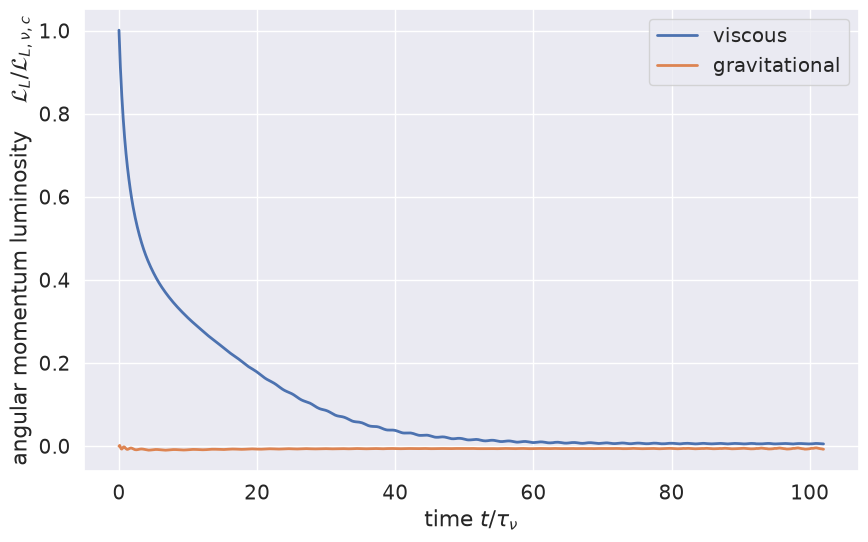

*Original epi_int_lite run (cell 30 of its nominal.ipynb):*

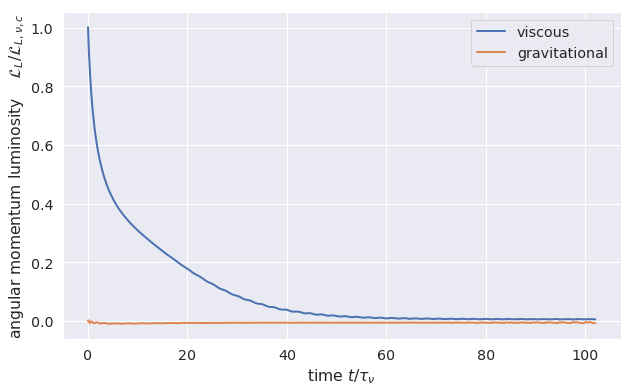

In [32]:
#plot angular momentum luminosity versus time
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = viscous_angular_momentum_luminosity/viscous_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscous')
y = grav_angular_momentum_luminosity/viscous_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravitational')
p = ax.set_ylabel(r'angular momentum luminosity    ${\cal L}_{L}/{\cal L}_{L,\nu,c}$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.legend()
plt.show()
show_original(30)

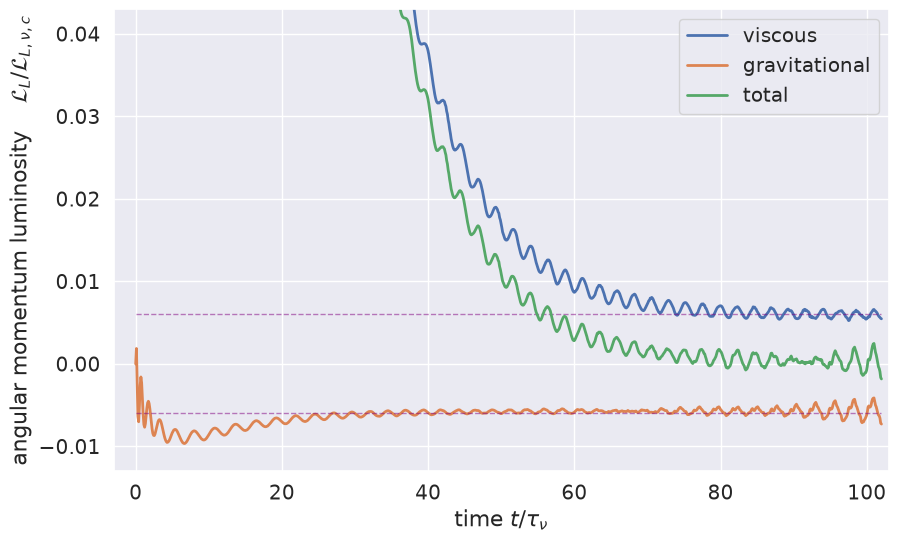

*Original epi_int_lite run (cell 31 of its nominal.ipynb):*

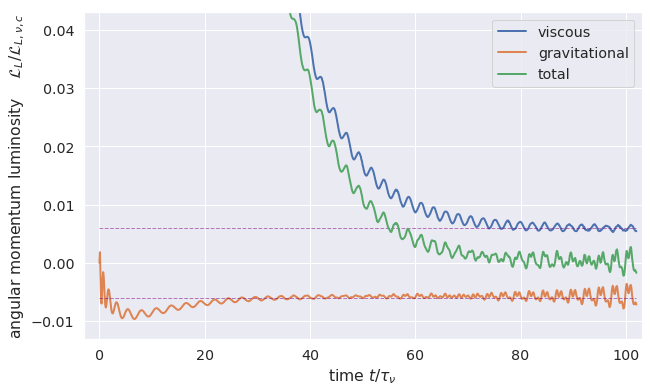

In [33]:
#plot angular momentum luminosity versus time
offset = 0.0060
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = viscous_angular_momentum_luminosity/viscous_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscous')
y = x*0 + offset
p = ax.plot(x, y, linestyle='dashed', linewidth=1, color='purple', alpha=0.5)
y = grav_angular_momentum_luminosity/viscous_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravitational')
y = x*0 - offset
p = ax.plot(x, y, linestyle='dashed', linewidth=1, color='purple', alpha=0.5)
y = (viscous_angular_momentum_luminosity + grav_angular_momentum_luminosity)/viscous_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='total')
p = ax.set_ylabel(r'angular momentum luminosity    ${\cal L}_{L}/{\cal L}_{L,\nu,c}$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylim(-0.013, 0.043)
p = ax.set_xlim(-3, 103)
p = ax.legend()
plt.show()
show_original(31)

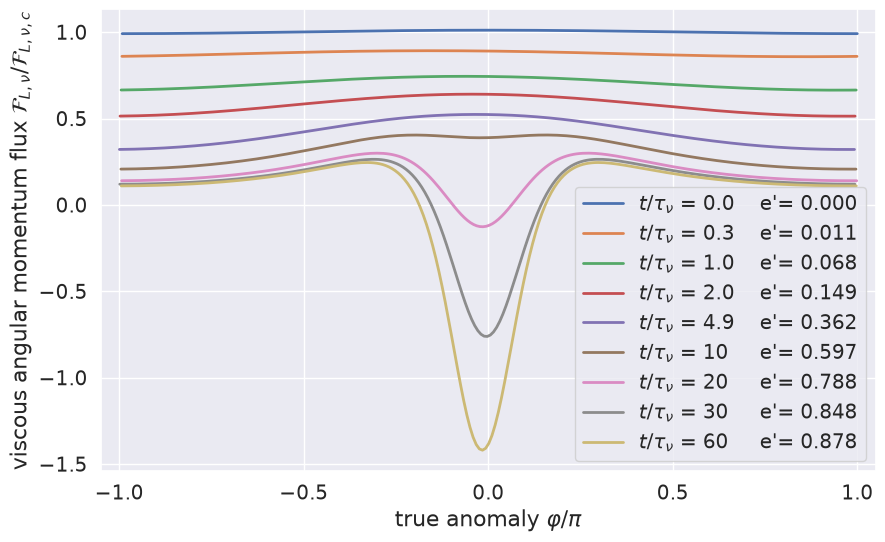

*Original epi_int_lite run (cell 32 of its nominal.ipynb):*

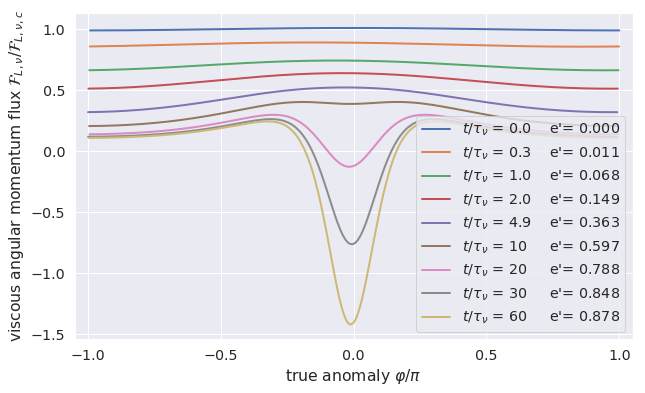

In [34]:
#plot viscous angular momentum flux vs longitude
f, ax = plt.subplots(figsize=(10, 6))
for plot_time in plot_times:
    t_idx = np.where(times_viscous >= plot_time)[0][0]
    angular_momentum_flux_now = viscous_angular_momentum_flux[t_idx]
    r_now = rc[t_idx]
    t_now = tc[t_idx]
    wt_now = wtc[t_idx]
    pidx = r_now.argmin()
    wt_min = wt_now[pidx]
    t_rotating = adjust_angle(t_now - wt_min)
    y = angular_momentum_flux_now/viscous_flux_circular
    x = t_rotating/np.pi
    idx = np.argsort(t_rotating)
    x = x[idx]
    y = y[idx]
    e_prime_now = e_prime[t_idx]
    lbl = r'$t/\tau_\nu$ = ' + str(times_viscous[t_idx])[0:3]
    if (lbl[-1] == '.'):
        lbl = lbl[0:-1] + ' '
    lbl += '    e\'= ' + '{:f}'.format(e_prime_now)[0:5]
    p = ax.plot(x, y, linestyle='-', linewidth=2, label=lbl)
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'viscous angular momentum flux ${\cal F}_{L,\nu}/{\cal F}_{L,\nu,c}$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = ax.set_xlim(-1.05, 1.05)
p = ax.legend(loc='lower right')
plt.show()
show_original(32)

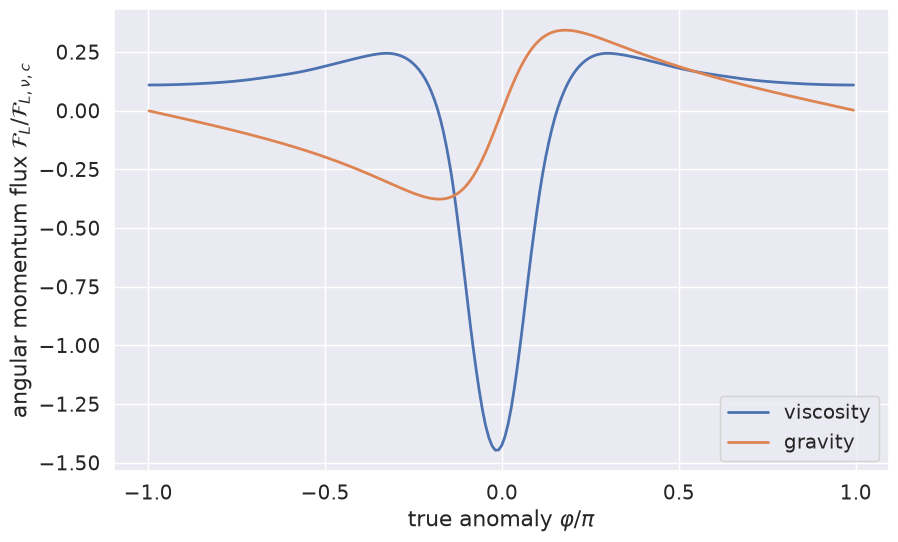

*Original epi_int_lite run (cell 33 of its nominal.ipynb):*

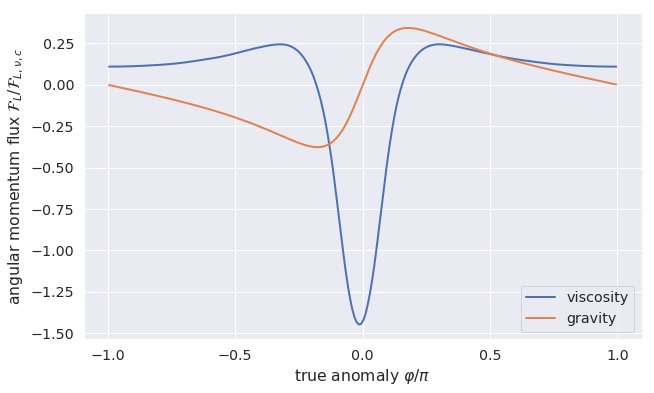

In [35]:
#plot final angular monentum fluxes vs longitude
f, ax = plt.subplots(figsize=(10, 6))
angular_momentum_flux_now = viscous_angular_momentum_flux[-1]
r_now = rc[-1]
t_now = tc[-1]
wt_now = wtc[-1]
pidx = r_now.argmin()
wt_min = wt_now[pidx]
t_rotating = adjust_angle(t_now - wt_min)
y = angular_momentum_flux_now/viscous_flux_circular
x = t_rotating/np.pi
idx = np.argsort(t_rotating)
x = x[idx]
y = y[idx]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscosity')
angular_momentum_flux_now = grav_angular_momentum_flux[-1]
y = angular_momentum_flux_now/viscous_flux_circular
y = y[idx]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravity')
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'angular momentum flux ${\cal F}_{L}/{\cal F}_{L,\nu,c}$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = ax.legend(loc='lower right')
plt.show()
show_original(33)

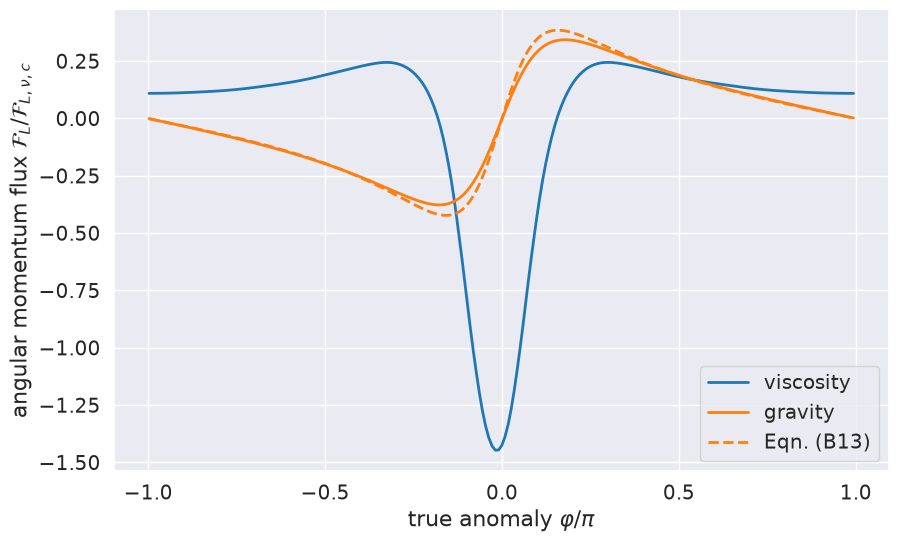

*Original epi_int_lite run (cell 34 of its nominal.ipynb):*

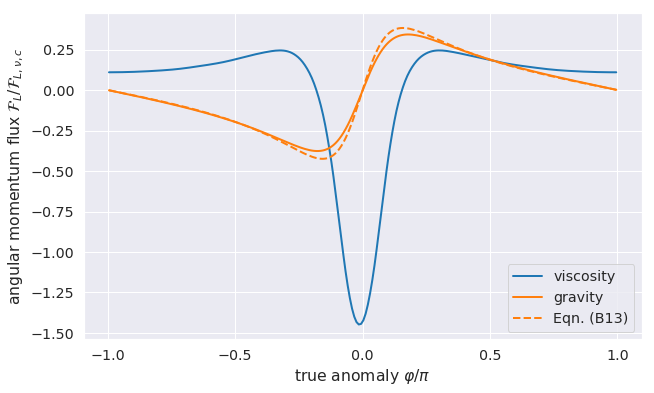

In [36]:
#plot final angular monentum fluxes vs longitude, with approximate formula with gravity
f, ax = plt.subplots(figsize=(10, 6))
angular_momentum_flux_now = viscous_angular_momentum_flux[-1]
y = angular_momentum_flux_now/viscous_flux_circular
x = t_rotating/np.pi
x = x[idx]
y = y[idx]
color = color_seq[0]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscosity', color=color)
angular_momentum_flux_now = grav_angular_momentum_flux[-1]
y = angular_momentum_flux_now/viscous_flux_circular
y = y[idx]
color = color_seq[1]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravity', color=color)
#approx gravity flux
a_now = a_mean[-1]
da_now = da[-1]
e_now = e_mean[-1]
e_prime_now = e_prime[-1]
wt_prime_now = wt_prime[-1]
lambda_now = total_ring_mass/(4*np.pi*a_now)
coeficient =  2*e_now*lambda_now*lambda_now*(a_now/da_now)
factor = np.sin(t_rotating)/(1 - e_prime_now*np.cos(t_rotating) - wt_prime_now*np.sin(t_rotating))
angular_momentum_flux_approx = coeficient*factor
y = angular_momentum_flux_approx/viscous_flux_circular
y = y[idx]
color = color_seq[1]
p = ax.plot(x, y, linestyle='dashed', linewidth=2, label='Eqn. (B13)', color=color)
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'angular momentum flux ${\cal F}_{L}/{\cal F}_{L,\nu,c}$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = ax.legend(loc='lower right')
plt.show()
show_original(34)

In [37]:
#compute viscous energy flux and luminosity
G = -1.0
c = -1.0
nu_s = shear_viscosity
nu_b = bulk_viscosity
viscous_energy_flux, viscous_energy_luminosity = calculate_energy_flux(
    total_ring_mass, number_of_streamlines, particles_per_streamline, J2, Rp, G,
    nu_s, nu_b, c, r, t, vr, vt, wt, times, fast_gravity, confine_inner_edge, confine_outer_edge)
viscous_energy_flux_circular = viscous_flux_circular*w0
viscous_energy_luminosity_circular = viscous_luminosity_circular*w0

In [38]:
#compute gravitational energy flux and luminosity
G = G_ring
c = -1.0
nu_s = -1.0
nu_b = -1.0
grav_energy_flux, grav_energy_luminosity = calculate_energy_flux(
    total_ring_mass, number_of_streamlines, particles_per_streamline, J2, Rp, G,
    nu_s, nu_b, c, r, t, vr, vt, wt, times, fast_gravity, confine_inner_edge, confine_outer_edge)

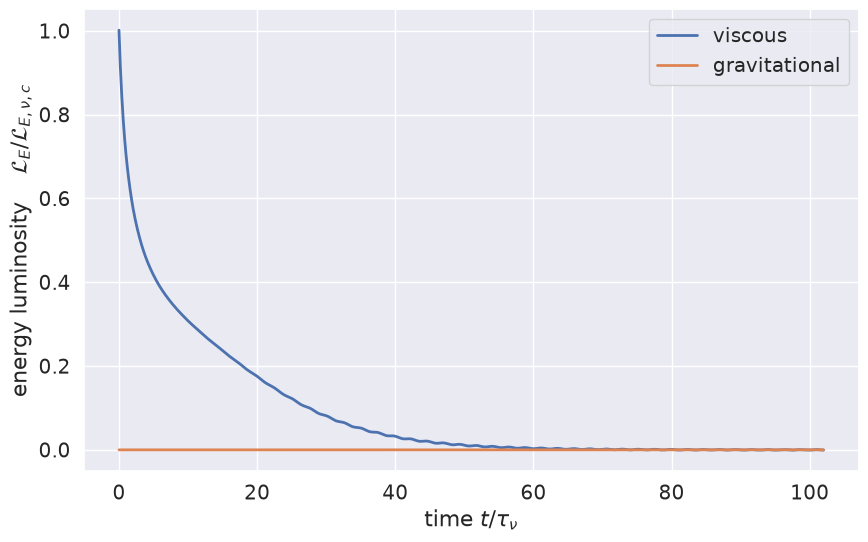

*Original epi_int_lite run (cell 37 of its nominal.ipynb):*

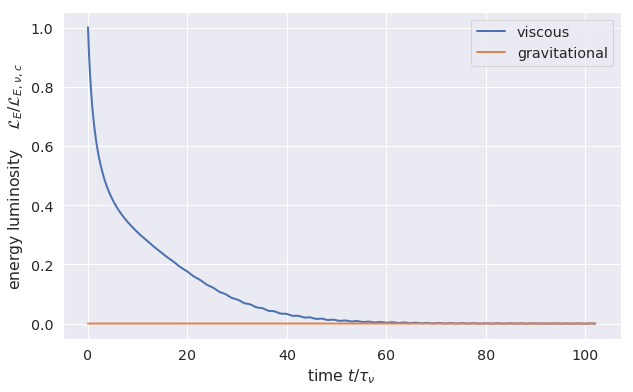

In [39]:
#plot energy luminosity versus time
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = viscous_energy_luminosity/viscous_energy_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscous')
y = grav_energy_luminosity/viscous_energy_luminosity_circular
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravitational')
p = ax.set_ylabel(r'energy luminosity    ${\cal L}_{E}/{\cal L}_{E,\nu,c}$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.legend()
plt.show()
show_original(37)

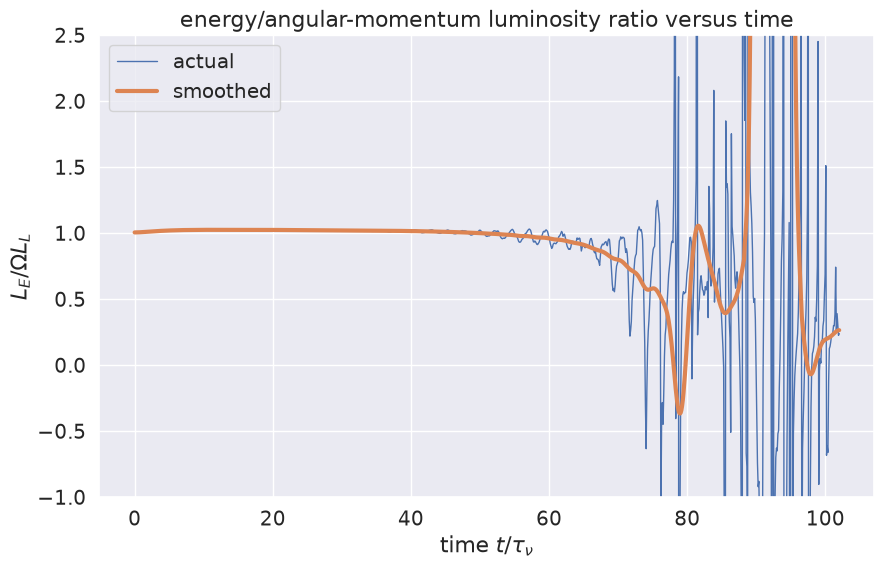

*Original epi_int_lite run (cell 38 of its nominal.ipynb):*

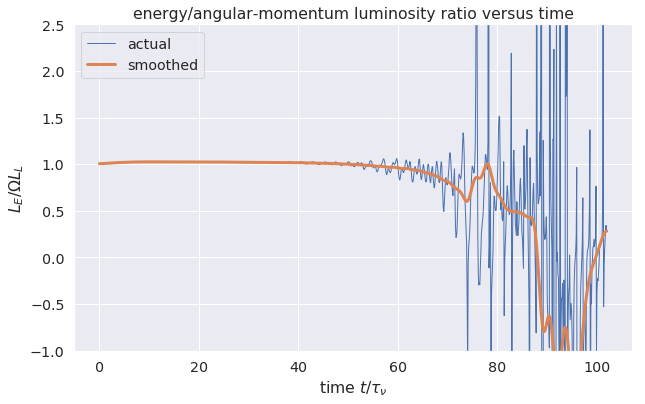

In [40]:
#plot L_E/(Omega*L_L) ratio
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
total_angular_momentum_luminosity = viscous_angular_momentum_luminosity + grav_angular_momentum_luminosity
total_energy_luminosity = viscous_energy_luminosity + grav_energy_luminosity
Omega_mean = Omega(J2, Rp, a_mean)
y = total_energy_luminosity/(Omega_mean*total_angular_momentum_luminosity)
p = ax.plot(x, y, linestyle='-', linewidth=1, label='actual')
from scipy.ndimage import gaussian_filter1d
ys = gaussian_filter1d(y, sigma=10)
p = ax.plot(x, ys, linestyle='-', linewidth=3, label='smoothed')
p = ax.set_title(r'energy/angular-momentum luminosity ratio versus time')
p = ax.set_ylabel(r'$L_E/\Omega L_L$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylim(-1.0, 2.5)
p = ax.legend()
plt.show()
show_original(38)

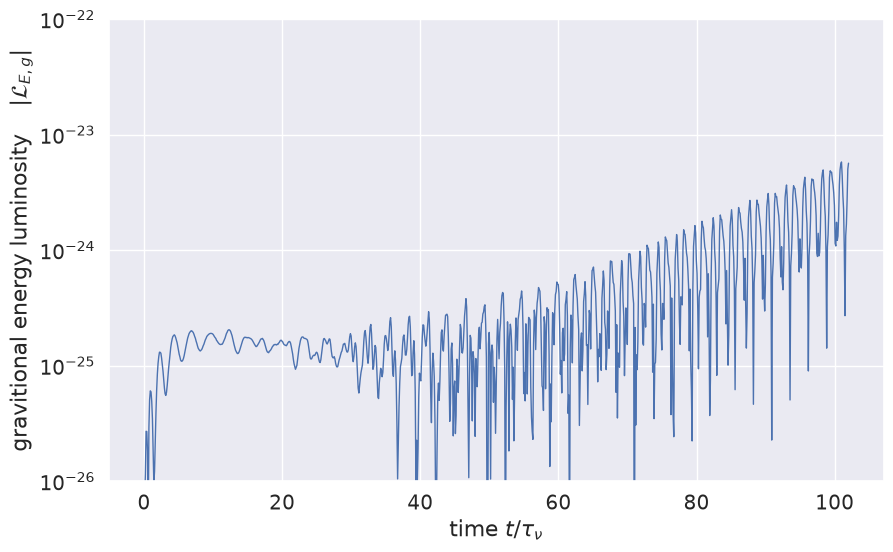

*Original epi_int_lite run (cell 39 of its nominal.ipynb):*

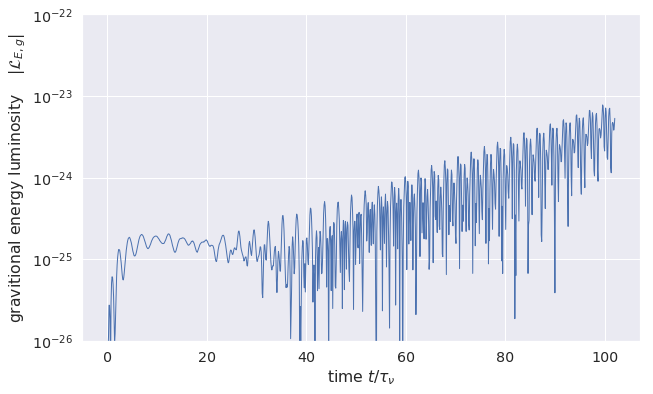

In [41]:
#plot grav_energy_luminosity versus time
f, ax = plt.subplots(figsize=(10, 6))
x = times_viscous
y = np.abs(grav_energy_luminosity)
p = ax.plot(x, y, linestyle='-', linewidth=1)
p = ax.set_ylabel(r'gravitional energy luminosity    $|{\cal L}_{E,g}|$')
p = ax.set_xlabel(r'time $t/\tau_\nu$')
p = ax.set_ylim(1.0e-26, 1.0e-22)
p = ax.set_yscale('log')
plt.show()
show_original(39)

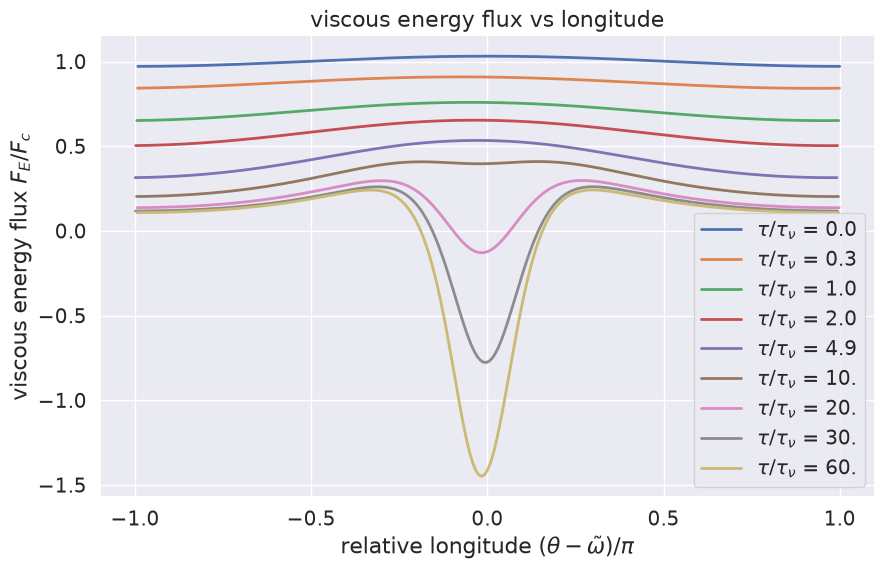

*Original epi_int_lite run (cell 40 of its nominal.ipynb):*

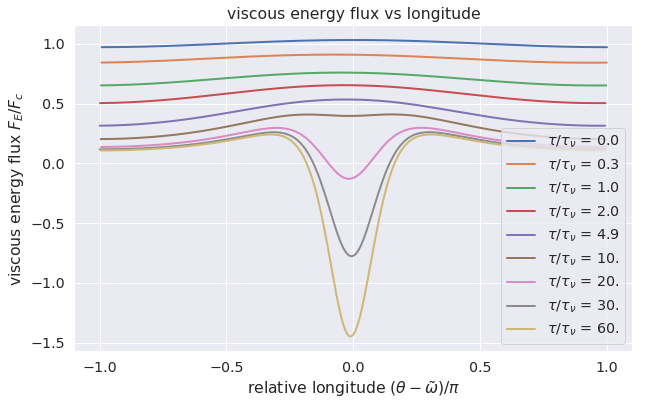

In [42]:
#plot viscous energy flux vs longitude
f, ax = plt.subplots(figsize=(10, 6))
for plot_time in plot_times:
    t_idx = np.where(times_viscous >= plot_time)[0][0]
    viscous_energy_flux_now = viscous_energy_flux[t_idx]
    r_now = rc[t_idx]
    t_now = tc[t_idx]
    wt_now = wtc[t_idx]
    pidx = r_now.argmin()
    wt_min = wt_now[pidx]
    t_rotating = adjust_angle(t_now - wt_min)
    y = viscous_energy_flux_now/viscous_energy_flux_circular
    x = t_rotating/np.pi
    idx = np.argsort(t_rotating)
    x = x[idx]
    y = y[idx]
    lbl = r'$\tau/\tau_\nu$ = ' + str(times_viscous[t_idx])[0:3]
    p = ax.plot(x, y, linestyle='-', linewidth=2, label=lbl)
p = ax.set_title(r'viscous energy flux vs longitude')
p = ax.set_xlabel(r'relative longitude $(\theta - \tilde{\omega})/\pi$')
p = ax.set_ylabel(r'viscous energy flux $F_E/F_c$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = ax.legend(loc='lower right')
plt.show()
show_original(40)

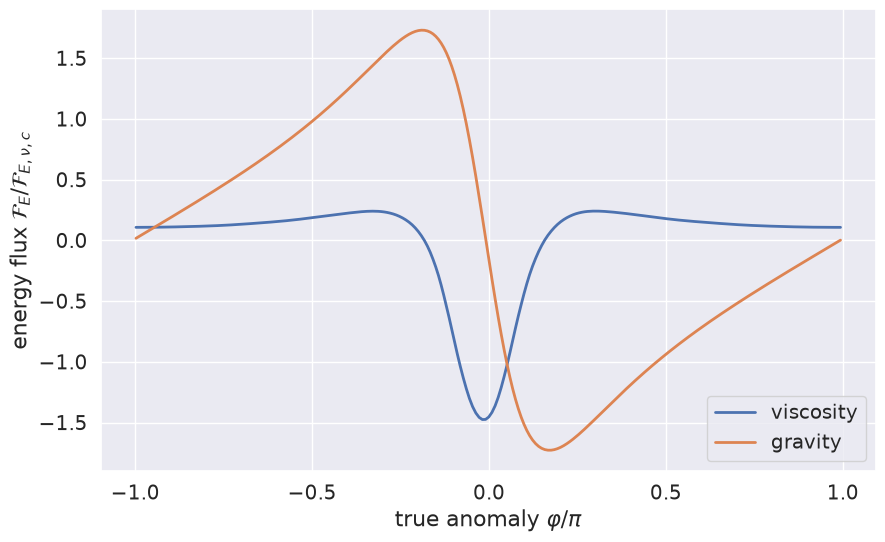

*Original epi_int_lite run (cell 41 of its nominal.ipynb):*

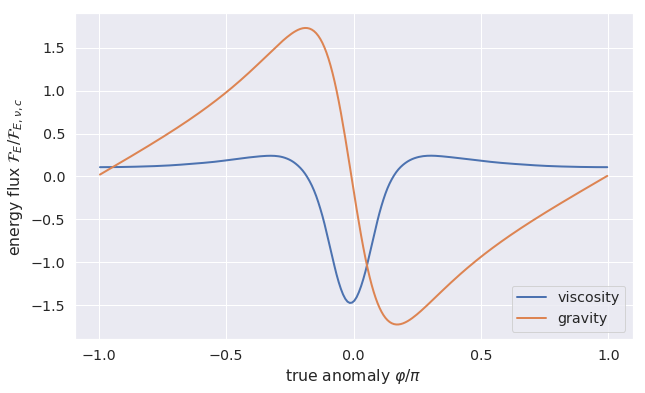

In [43]:
#plot final energy fluxes vs longitude
f, ax = plt.subplots(figsize=(10, 6))
energy_flux_now = viscous_energy_flux[-1]
r_now = rc[-1]
t_now = tc[-1]
wt_now = wtc[-1]
pidx = r_now.argmin()
wt_min = wt_now[pidx]
t_rotating = adjust_angle(t_now - wt_min)
y = energy_flux_now/viscous_energy_flux_circular
x = t_rotating/np.pi
idx = np.argsort(t_rotating)
x = x[idx]
y = y[idx]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='viscosity')
energy_flux_now = grav_energy_flux[-1]
y = 100*energy_flux_now/viscous_energy_flux_circular
y = y[idx]
p = ax.plot(x, y, linestyle='-', linewidth=2, label='gravity')
p = ax.set_xlabel(r'true anomaly $\varphi/\pi$')
p = ax.set_ylabel(r'energy flux ${\cal F}_{E}/{\cal F}_{E,\nu,c}$')
p = ax.xaxis.set_major_locator(plt.MaxNLocator(5))
p = plt.legend(loc='lower right')
plt.show()
show_original(41)

## Numbers printed by the original notebook

The original epi_int_lite run (its nominal.ipynb, Python 2, 2025) versus this epi_int_3d run.

In [44]:
#the numbers the original notebook printed, versus this run's
compare = {
    'e.min()': (0.009739907822548672, e.min()),
    'e.max()': (0.01023265987927087, e.max()),
    'a[0][1].mean()': (1.0001001598217623, a[0][1].mean()),
    'e-damping a0': (1.0000500326636725, a_mean[100]),
    'e-damping e0': (0.009999425149834072, e_mean[100]),
    'total_angular_momentum[0]': (1.0018981045559237e-10, total_angular_momentum[0]),
    'max fractional angular momentum change': (9.843362697619581e-08, fractional_angular_momentum_change.max()),
    'dynamical_timescale': (85000.0, dynamical_timescale),
    "e' at output 56": (0.3994869044466735, e_prime[56]),
    "e' at output 116": (0.6460922315573672, e_prime[116]),
    "e' at output 187": (0.7784182021422331, e_prime[187]),
    "e' at output 702": (0.879638362020972, e_prime[702]),
    'periapse sigma/sigma_0 (inner)': (3.57499486, sd_peri[1]),
    'periapse sigma/sigma_0 (outer)': (3.58822574, sd_peri[2]),
    'apoapse sigma/sigma_0 (inner)': (0.26211045, sd_apo[1]),
    'apoapse sigma/sigma_0 (outer)': (0.26212411, sd_apo[2]),
    'viscous_luminosity_circular': (7.513667836103645e-20, viscous_luminosity_circular),
    'execution time (min)': (50.05, (monitor['current_time'] - monitor['start_time'])/60.0),
    }
df = pd.DataFrame(compare, index=['epi_int_lite (original)', 'epi_int_3d']).T
df['fractional_difference'] = df['epi_int_3d']/df['epi_int_lite (original)'] - 1
pd.set_option('display.float_format', lambda x: f'{x:.6g}')
df

,epi_int_lite (original),epi_int_3d,fractional_difference
e.min(),0.00973991,0.00974072,8.33558e-05
e.max(),0.0102327,0.0102331,4.10744e-05
a[0][1].mean(),1.0001,1.0001,1.99505e-11
e-damping a0,1.00005,1.00005,-6.7129e-10
e-damping e0,0.00999943,0.00999948,5.08422e-06
total_angular_momentum[0],1.0019e-10,1.0019e-10,7.9301e-12
max fractional angular momentum change,9.84336e-08,9.19785e-08,-0.0655783
dynamical_timescale,85000,85000,0
e' at output 56,0.399487,0.399408,-0.000197637
e' at output 116,0.646092,0.646028,-9.92221e-05
